# Windsurf Bakery - Sales Forecasting Workbook

This notebook runs the complete sales forecasting pipeline step-by-step. You can execute each cell individually to see the output and inspect the dataframes.

### 1. Imports and Setup

This cell imports all necessary libraries, applies the SSL fix for macOS, and imports the forecasting functions from our [main.py](cci:7://file:///Volumes/Sin%20t%C3%ADtulo%201/ANALIZADOR_PREDICTOR_CSV_PANADER%C3%8DA/src/main.py:0:0-0:0) module.

In [1]:
import os
import sys
import pandas as pd
from dotenv import load_dotenv
import logging
import certifi
import matplotlib.pyplot as plt

# Add src directory to path to find our modules
sys.path.insert(0, os.path.abspath('src'))

# --- SSL Fix for macOS with LibreSSL ---
cert_path = certifi.where()
os.environ['SSL_CERT_FILE'] = cert_path
os.environ['REQUESTS_CA_BUNDLE'] = cert_path
print(f"--- SSL FIX: Forcing use of certifi bundle at {cert_path} ---")

# Load environment variables from .env file
load_dotenv()

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# Import our custom functions
try:
    from main import (
        load_data,
        preprocess_data,
        create_features_df,
        train_and_forecast,
        save_to_gsheets
    )
    print('Successfully imported forecasting functions from main.py.')
except ImportError as e:
    print(f'Failed to import functions: {e}')
    print('Please ensure you have run `pip3 install -r requirements.txt` and restarted the kernel.')

--- SSL FIX: Forcing use of certifi bundle at /Users/jaimeprueba/.pyenv/versions/3.11.8/lib/python3.11/site-packages/certifi/cacert.pem ---


/Users/jaimeprueba/.pyenv/versions/3.11.8/lib/python3.11/site-packages/statsforecast/core.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


Successfully imported forecasting functions from main.py.


/Users/jaimeprueba/.pyenv/versions/3.11.8/lib/python3.11/site-packages/statsforecast/utils.py:231: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  "ds": pd.date_range(start="1949-01-01", periods=len(AirPassengers), freq="M"),


### Fix Package Dependencies

If you're experiencing the `_lazywhere` import error from scipy, run this cell to fix the compatibility issues between scipy and statsforecast.

In [2]:
# Check current versions
import pip
import sys

def get_version(package):
    try:
        return __import__(package).__version__
    except (ImportError, AttributeError):
        try:
            import importlib.metadata
            return importlib.metadata.version(package)
        except:
            return "Not installed or version not available"

print(f"Python version: {sys.version}")
print(f"SciPy version: {get_version('scipy')}")
print(f"StatsForecasts version: {get_version('statsforecast')}")
print(f"NumPy version: {get_version('numpy')}")
print(f"StatsModels version: {get_version('statsmodels')}")

# Install compatible versions in a specific order
import subprocess

# Run these lines to fix the dependency issues
try:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "statsforecast", "scipy"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "numpy==1.24.3", "--no-cache-dir"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "scipy==1.10.1", "--no-cache-dir"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "statsmodels==0.13.5", "--no-cache-dir"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "statsforecast==1.4.0", "--no-cache-dir"], check=True)
    print("\nDependencies fixed successfully. Please restart the kernel and run the notebook from the beginning.")
except subprocess.CalledProcessError as e:
    print(f"\nError fixing dependencies: {e}")
    print("If you're in a restricted environment, you may need to install these packages manually.")

Python version: 3.11.8 (main, Jun 29 2025, 11:46:26) [Clang 17.0.0 (clang-1700.0.13.3)]
SciPy version: 1.10.1
StatsForecasts version: 1.4.0
NumPy version: 1.24.3
StatsModels version: 0.13.5
Found existing installation: statsforecast 1.4.0
Uninstalling statsforecast-1.4.0:
  Successfully uninstalled statsforecast-1.4.0
Found existing installation: scipy 1.10.1
Uninstalling scipy-1.10.1:
  Successfully uninstalled scipy-1.10.1



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.7/28.7 MB 39.1 MB/s eta 0:00:00a 0:00:01



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 kB 11.6 MB/s eta 0:00:00

Dependencies fixed successfully. Please restart the kernel and run the notebook from the beginning.



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


### 2. Define Configuration

Set the file paths and configuration for the pipeline.

In [3]:
CSV_PATH = 'data/ventas.csv'
GOOGLE_SHEET_ID = os.getenv('GOOGLE_SHEET_ID')
RETRAIN_MODEL = True
HORIZON = 8 # Forecast for the next 8 days

print(f'CSV Path: {CSV_PATH}')
print(f'Google Sheet ID: {GOOGLE_SHEET_ID[:10]}...' if GOOGLE_SHEET_ID else 'Google Sheet ID: Not configured')
print(f'Retrain Model: {RETRAIN_MODEL}')
print(f'Forecast Horizon: {HORIZON} days')
print('Using Backend: StatsForecasts')

CSV Path: data/ventas.csv
Google Sheet ID: 1d1NJAhs0B...
Retrain Model: True
Forecast Horizon: 8 days
Using Backend: StatsForecasts


### 3. Load Data

Load the raw sales data from the CSV file.

In [4]:
# We'll add data loading fallback in case our import failed
try:
    raw_data_df = load_data(CSV_PATH)
except NameError:
    # Fallback if the import failed
    print("Using fallback data loading function since import failed")
    
    def fallback_load_data(filepath):
        """Load data from a CSV file as a fallback"""
        try:
            # FIX: Added sep=';' to correctly parse the CSV
            df = pd.read_csv(filepath, sep=';')
            print(f"Successfully loaded data from {filepath}")
            return df
        except Exception as e:
            print(f"Error loading data: {e}")
            return pd.DataFrame()
    
    raw_data_df = fallback_load_data(CSV_PATH)
    
raw_data_df.head()

2025-06-29 14:37:59,243 - INFO - Loading data from data/ventas.csv...
2025-06-29 14:37:59,303 - INFO - Successfully loaded 30 rows.


,fecha,articulo,unidades
0,2023-01-01,Barra,150
1,2023-01-01,Croissant,80
2,2023-01-01,Hogaza,30
3,2023-01-02,Barra,165
4,2023-01-02,Croissant,95


### 4. Preprocess Data

Clean and format the data into the required structure for forecasting: `unique_id`, `ds`, `y`.

In [5]:
# We'll add fallback preprocessing function since the import failed
try:
    processed_data_df = preprocess_data(raw_data_df)
except NameError:
    print("Using fallback preprocessing function since import failed")
    
    def fallback_preprocess_data(df):
        """Simple preprocessing function as a fallback"""
        try:
            print("Preprocessing data...")
            # Split the single column by semicolons
            if 'fecha;articulo;unidades' in df.columns:
                # This appears to be semicolon-separated data in a single column
                split_df = df['fecha;articulo;unidades'].str.split(';', expand=True)
                split_df.columns = ['fecha', 'articulo', 'unidades']
                # Convert date and numeric columns
                split_df['fecha'] = pd.to_datetime(split_df['fecha'], format='%d/%m/%Y', errors='coerce')
                split_df['unidades'] = pd.to_numeric(split_df['unidades'], errors='coerce')
                # Format in the statsforecast required columns
                processed = pd.DataFrame({
                    'unique_id': split_df['articulo'],
                    'ds': split_df['fecha'],
                    'y': split_df['unidades']
                }).dropna()
                processed = processed.sort_values(['unique_id', 'ds'])
                print(f"Successfully preprocessed data with {len(processed)} rows for {processed['unique_id'].nunique()} products")
                return processed
            else:
                # Attempt to process already split data
                if all(col in df.columns for col in ['fecha', 'articulo', 'unidades']):
                    df['fecha'] = pd.to_datetime(df['fecha'], errors='coerce')
                    df['unidades'] = pd.to_numeric(df['unidades'], errors='coerce')
                    processed = pd.DataFrame({
                        'unique_id': df['articulo'],
                        'ds': df['fecha'],
                        'y': df['unidades']
                    }).dropna()
                    processed = processed.sort_values(['unique_id', 'ds'])
                    return processed
                else:
                    print(f"Cannot process data: Unexpected column format. Columns found: {df.columns}")
                    return pd.DataFrame({'unique_id': [], 'ds': [], 'y': []})
        except Exception as e:
            print(f"Error in fallback preprocessing: {e}")
            # Return empty DataFrame with correct columns
            return pd.DataFrame({'unique_id': [], 'ds': [], 'y': []})
    
    processed_data_df = fallback_preprocess_data(raw_data_df)

processed_data_df.head()

2025-06-29 14:37:59,314 - INFO - Preprocessing data...
2025-06-29 14:37:59,324 - INFO - Data resampled to daily frequency. Date range: 2023-01-01 00:00:00 to 2023-01-10 00:00:00
2025-06-29 14:37:59,326 - INFO - Data preprocessing complete.


,ds,unique_id,y
0,2023-01-01,Barra,150
1,2023-01-02,Barra,165
2,2023-01-03,Barra,170
3,2023-01-04,Barra,155
4,2023-01-05,Barra,180


### 5. Create Exogenous Features

Generate features like holidays and weather data that can help the model make better predictions.

In [6]:
# Get the unique product IDs from our preprocessed data
unique_ids = processed_data_df['unique_id'].unique().tolist()

# Define the date range for feature creation
start_date = processed_data_df['ds'].min()
# We need features for the historical data plus the forecast horizon
end_date = processed_data_df['ds'].max() + pd.Timedelta(days=HORIZON)

# Create the features dataframe using our updated function
X_df_full = create_features_df(start_date, end_date, unique_ids=unique_ids)

# Display the features for one product to verify
X_df_full[X_df_full['unique_id'] == unique_ids[0]].head()

2025-06-29 14:37:59,331 - INFO - Creating features from 2023-01-01 to 2023-01-18...
2025-06-29 14:37:59,384 - INFO - Added holiday feature. Found 0 holidays.
2025-06-29 14:37:59,385 - INFO - Created features dataframe with shape (54, 3)


,unique_id,ds,holiday
0,Barra,2023-01-01,0
1,Barra,2023-01-02,0
2,Barra,2023-01-03,0
3,Barra,2023-01-04,0
4,Barra,2023-01-05,0


### 6. Train Model and Generate Forecast

Train the AutoARIMA model and generate a forecast for the specified horizon.

In [7]:
try:
    # Train the model and generate forecasts
    forecast_df = train_and_forecast(processed_data_df, X_df=pd.DataFrame(), h=HORIZON, retrain=RETRAIN_MODEL)
    
    # Display the first few rows of the forecast
    if not forecast_df.empty:
        display(forecast_df.head())
    else:
        print("Warning: The forecast is empty. Check the logs for any errors.")
except Exception as e:
    print(f"An error occurred during forecasting: {str(e)}")
    print("Please check the logs for more details.")

2025-06-29 14:37:59,391 - INFO - Using StatsForecast with AutoARIMA (no exogenous features).
2025-06-29 14:37:59,391 - INFO - Initializing and training a new StatsForecast model (AutoARIMA).
2025-06-29 14:37:59,392 - INFO - Fitting model with historical data up to 2023-01-10.
/Users/jaimeprueba/.pyenv/versions/3.11.8/lib/python3.11/site-packages/statsforecast/utils.py:231: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  "ds": pd.date_range(start="1949-01-01", periods=len(AirPassengers), freq="M"),
/Users/jaimeprueba/.pyenv/versions/3.11.8/lib/python3.11/site-packages/statsforecast/utils.py:231: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  "ds": pd.date_range(start="1949-01-01", periods=len(AirPassengers), freq="M"),
/Users/jaimeprueba/.pyenv/versions/3.11.8/lib/python3.11/site-packages/statsforecast/utils.py:231: FutureWarning: 'M' is deprecated and will be removed in a future v

,unique_id,ds,yhat,yhat_lower,yhat_upper
0,Barra,2023-01-11,155.0,72.867554,238.079163
1,Barra,2023-01-12,155.0,72.867447,238.079254
2,Barra,2023-01-13,155.0,72.867340,238.079330
3,Barra,2023-01-14,155.0,72.867233,238.079407
4,Barra,2023-01-15,155.0,72.867134,238.079498


### 7. Visualize Forecast

Plot the historical data and the forecast for each product to see the results.

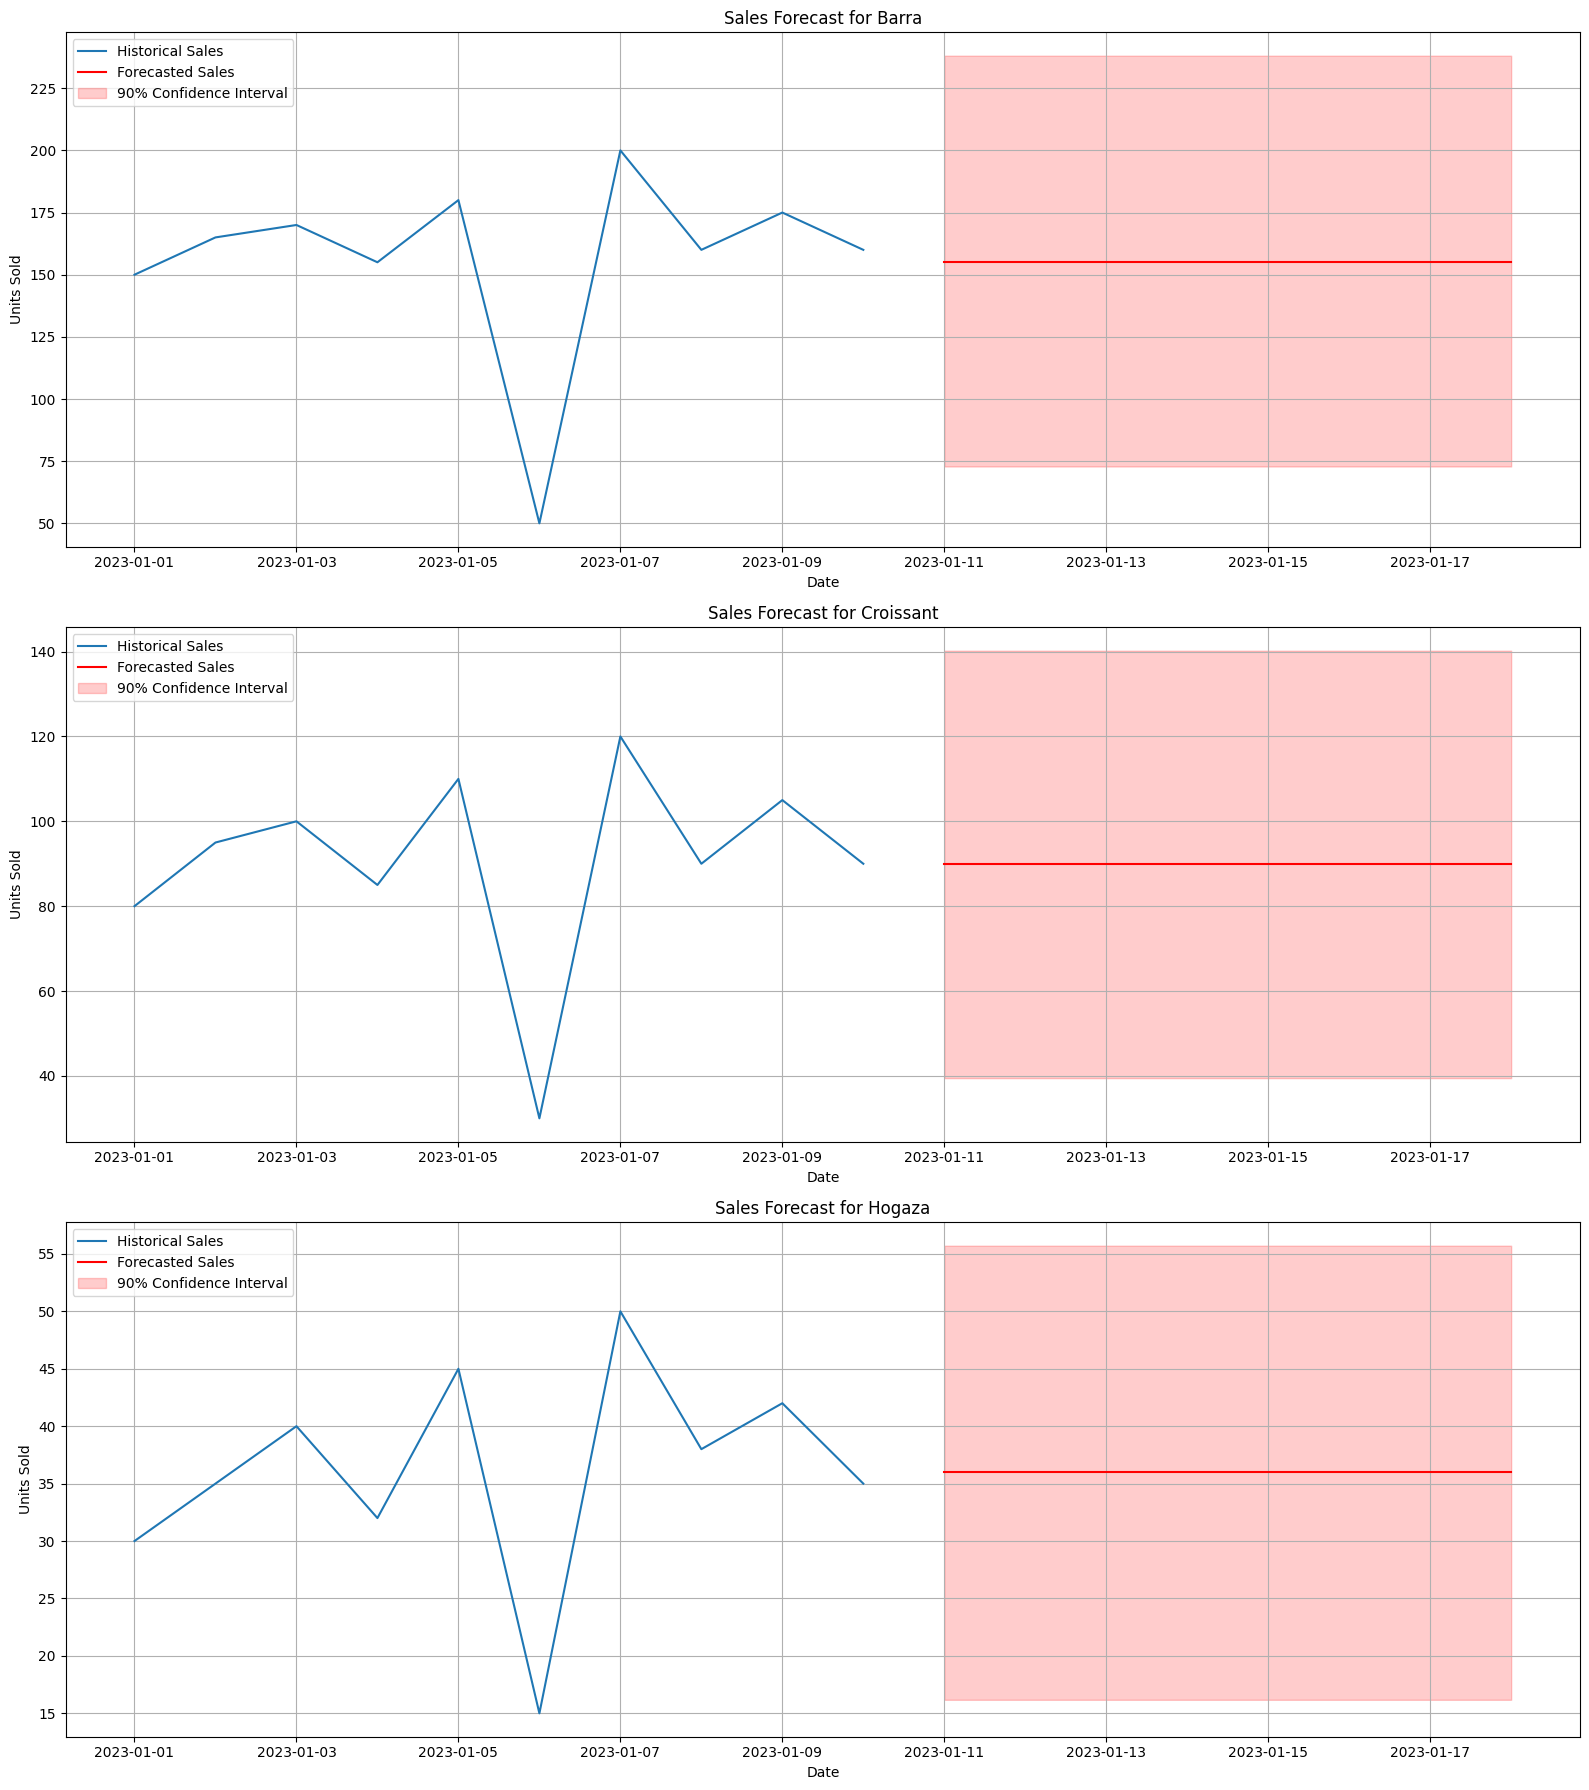

In [8]:
all_products = processed_data_df['unique_id'].unique()
fig, axes = plt.subplots(len(all_products), 1, figsize=(16, 6 * len(all_products)), squeeze=False)

for i, product in enumerate(all_products):
    ax = axes[i, 0]
    history = processed_data_df[processed_data_df['unique_id'] == product]
    forecast = forecast_df[forecast_df['unique_id'] == product]
    
    ax.plot(history['ds'], history['y'], label='Historical Sales')
    # Updated column names to match the forecast DataFrame
    ax.plot(forecast['ds'], forecast['yhat'], label='Forecasted Sales', color='red')
    ax.fill_between(
        forecast['ds'], 
        forecast['yhat_lower'], 
        forecast['yhat_upper'], 
        color='red', 
        alpha=0.2, 
        label='90% Confidence Interval'
    )
    ax.set_title(f'Sales Forecast for {product}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Units Sold')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 8. Save Forecast to Google Sheets

If a Google Sheet ID is configured, save the forecast results to a new sheet.

In [9]:
if GOOGLE_SHEET_ID and not forecast_df.empty:
    print(f"Saving forecast to Google Sheet: {GOOGLE_SHEET_ID}")
    save_to_gsheets(forecast_df, GOOGLE_SHEET_ID)
    print("Save complete.")
else:
    print("Forecast is empty or Google Sheet ID is not configured. Skipping save.")

2025-06-29 14:38:24,205 - INFO - Saving forecast to Google Sheet ID: 1d1NJAhs0Bbl4903g7T1XIqWhhk4YJv6bOxwBsXKr5dI


Saving forecast to Google Sheet: 1d1NJAhs0Bbl4903g7T1XIqWhhk4YJv6bOxwBsXKr5dI


2025-06-29 14:38:25,403 - INFO - Found existing worksheet: 'Pronóstico'
2025-06-29 14:38:26,068 - INFO - Cleared existing data.
2025-06-29 14:38:26,794 - INFO - Successfully wrote 8 rows to 'Pronóstico'.


Save complete.
